## Taylor series interpretation of Feedback parameters
Here, I see if I can get a more physical interpretation of feedback parameters.

In [1]:
import sys
import os

from isca_tools.thesis.surface_flux_taylor_2layer import get_sensitivity_lh
from isca_tools.utils.numerical import sum_complex

# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
from isca_tools.utils.constants import kappa, L_v, c_p, c_p_ocean, rho_ocean, Stefan_Boltzmann, R, R_v, g, radius_earth

import numpy as np
import matplotlib.pyplot as plt

from jobs.thesis_season.publish_figs.load import load_ds, var_keep, lat_target, spline_deriv_periodic_xr, \
    day_seconds, process_ds, get_fourier_fit_xr
from isca_tools.plot import fig_resize
# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

In [2]:
from jobs.thesis_season.publish_figs.load import load_ds_all, width, day_seconds, exclude_params, params_all, label_temp
from jobs.thesis_season.publish_figs.energy_budget_empirical import get_approx_flux_atmos, get_empirical_params, \
    get_approx_mse_tend, get_heat_cap_lambda_eff
from jobs.thesis_season.publish_figs.xr_funcs import get_fit_complex_xr, apply_linear_zero_mean_xr, get_fourier_fit_xr

exp_name = 'base'
ds = load_ds_all(exp_name)
feedback_params = get_empirical_params(ds, exclude_params=exclude_params[exp_name])

Loaded dataset from:
/Users/joshduffield/Documents/StAndrews/Isca/jobs/thesis_season/publish_figs/processed_data/ds_base.nc


### Phase of $\Lambda$
Here, we show that the phase of $\Lambda$ is negative because the phase of relative humidity is positive (i.e., relative humidity lags behind low level temperature) but the sensitivity of latent heat to relative humidity is negative. I.e., $\frac{\partial \chi}{\partial r_a}\beta_r\sin(\phi_r)<0$ in the below derivation, but the real part $\frac{\partial \chi}{\partial r_a}\beta_r\cos(\phi_r) + \frac{\partial \chi}{\partial T_a} + \frac{\partial \chi}{\partial T_s}$ is positive. Where $\chi$ is latent heat flux.

\begin{equation}
    r_a' \approx \beta_r T_a' e^{-i\phi_r}.
\end{equation}

\begin{equation}
\begin{aligned}
    \chi
    &\approx
    \frac{\partial \chi}{\partial T_s} T_s'
    + \frac{\partial \chi}{\partial T_a} T_a'
    + \frac{\partial \chi}{\partial r_a} r_a'
    \\[6pt]
    &=
    \frac{\partial \chi}{\partial T_s} T_s'
    + \left[
        \frac{\partial \chi}{\partial T_a}
        + \frac{\partial \chi}{\partial r_a}
          \beta_r e^{-i\phi_r}
      \right] T_a'
    \\[6pt]
    &=
    \frac{\partial \chi}{\partial T_s}
    \left(T_s' - T_a'\right)
    + \left[
        \frac{\partial \chi}{\partial T_a}
        + \frac{\partial \chi}{\partial r_a}
          \beta_r e^{-i\phi_r}
        + \frac{\partial \chi}{\partial T_s}
      \right] T_a'
    \\[6pt]
    &=
    \lambda \left(T_s' - T_a'\right)
    + \Lambda e^{-i\phi_{\Lambda}} T_a'.
\end{aligned}
\end{equation}

In [3]:
ds_use = ds.mean(dim='time')
sens_lh = get_sensitivity_lh(ds_use.temp_surf, ds_use.temp_atm, ds_use.rh_atm, ds.wind_drag_av, 1, ds_use.p_surf, ds_use.sigma_atm)
coef_amp_rh, coef_phase_rh = get_fit_complex_xr(ds.temp_atm, ds.rh_atm, ds.time, True)

feedback_params_taylor = {}
feedback_params_taylor['lambda_a_lh'], feedback_params_taylor['coef_phase_a_lh'] = \
    sum_complex((feedback_params['lambda_const_lh'], 0), (sens_lh['temp_atm'], 0),
                (sens_lh['rh_atm']*coef_amp_rh, coef_phase_rh))

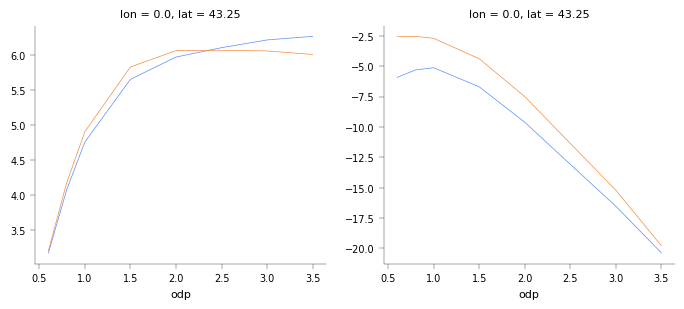

In [4]:
fig, ax = plt.subplots(1, 2)
fig_resize(fig, width['two_col'] * 1.5)
feedback_params['lambda_a_lh'].plot(ax=ax[0])
feedback_params_taylor['lambda_a_lh'].plot(ax=ax[0])
(feedback_params['coef_phase_a_lh'] / ds.omega / day_seconds).plot(ax=ax[1])
(feedback_params_taylor['coef_phase_a_lh'] / ds.omega / day_seconds).plot(ax=ax[1])

### OLR
Below I define an OLR radiative temperature such that $OLR = \epsilon \sigma T_{OLR}^4$ with $\epsilon = 1 - \exp(-\tau_s)$ with $\tau_s$ being the longwave surface optical depth.

Then if $T_{OLR}' = \beta_{OLR}T_a'\exp(-i\phi_{Tolr})$, we have $OLR' \approx 4\sigma \epsilon \overline{T}_{OLR}^3 \beta_{OLR}T_a'\exp(-i\phi_{Tolr})$

And thus if $OLR' = BT_a\exp(-i\phi_B)$ we have $B \approx 4\sigma \epsilon \overline{T}_{OLR}^3 \beta_{OLR}$ and $\phi_B = \phi_{Tolr}$.

But we note that $\epsilon \overline{T}_{OLR}^3$ does not vary much with optical depth, so we approximate $B$ further:
$B \approx 4\sigma <\epsilon \overline{T}_{OLR}^3> \beta_{OLR}$ where $<\chi>$ is the reference value of $\chi$ at $\kappa=1.5$.

So the variation of $B$ with optical depth is due almost entirely to $\beta_{OLR}$ increasing with warming. I.e., in a warmer world the increase in the radiative temperature per increase in low level temperature is larger, hence more efficient cooling. This is the same lapse rate type explanation as the column mean temperature coefficient.

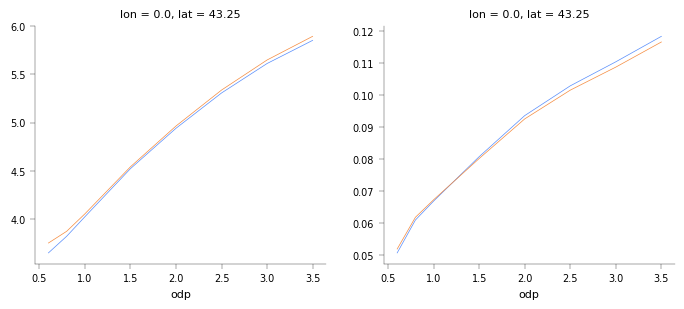

In [8]:
emiss_factor = 1 - np.exp(-ds.odp_surf)
temp_olr = (ds.olr / (Stefan_Boltzmann*emiss_factor))**0.25
coef_amp_temp_olr, feedback_params_taylor['coef_phase_olr'] = get_fit_complex_xr(ds.temp_atm, temp_olr, ds.time, True)
feedback_params_taylor['B'] = (4 * Stefan_Boltzmann * emiss_factor * temp_olr.mean(dim='time')**3).sel(odp=1.5)*coef_amp_temp_olr

fig, ax = plt.subplots(1, 2)
fig_resize(fig, width['two_col'] * 1.5)
feedback_params['B'].plot(ax=ax[0])
feedback_params_taylor['B'].plot(ax=ax[0])
feedback_params['coef_phase_olr'].plot(ax=ax[1])
feedback_params_taylor['coef_phase_olr'].plot(ax=ax[1])
plt.show()

### Moisture component of MSE tendency, $\mu$
The parameter $\mu$ is obtained from regression of column specific humidity against lowest model level temperature so
$L_vq_{col}' \approx c_p \mu T_a'$

Just say clausius clapeyron:
"The increase in \mu with warming is consistent with Clausius–Clapeyron scaling. For approximately constant column relative humidity, $q_{col}$ increases at roughly 7% K⁻¹, so $\mu \approx (L_v/c_p)\,\alpha\, q_{col}$ with $\alpha\approx 0.07$ K⁻¹ (black dashed line)."

Can say this as column relative humidity is constant at around 70%.

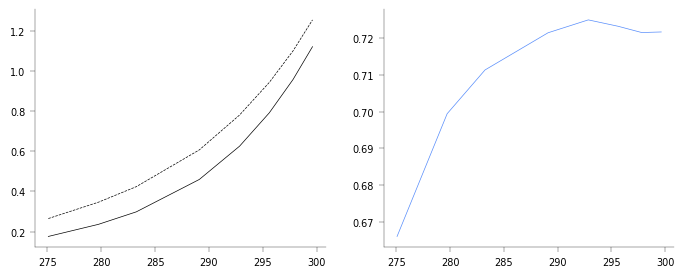

In [6]:
def mu_estimate(q_col, alpha, T=None):
    """
    Rule-of-thumb mu from L_v q_col' ≈ c_p mu T_a', assuming constant column RH
    so that q_col' = alpha * q_col * T_a'.

    q_col : column-mean specific humidity [kg/kg]
            (if it is a column integral in kg/m^2, pass ps [Pa] and it is converted)
    alpha : fractional CC rate [1/K]; default 0.07
    T     : optional temperature [K]; if given, alpha = L_v / (R_v T^2)
    """
    q_col = np.asarray(q_col, dtype=float)
    if T is not None:
        alpha = L_v / (R_v * np.asarray(T, dtype=float) ** 2)
    return (L_v / c_p) * alpha * q_col

fig, ax = plt.subplots(1, 2, sharex=True)
fig_resize(fig, width['two_col'] * 1.5)
ax[0].plot(ds.temp_surf.mean(dim='time'), feedback_params['mu'], color='k')
ax[0].plot(ds.temp_surf.mean(dim='time'), mu_estimate(ds.sphum_col.mean(dim='time'), alpha=0.07), color='k', linestyle='--')
ax[1].plot(ds.temp_surf.mean(dim='time'), ds.rh_col.mean(dim='time'))